## ═══════════════════════════════════════════════════
## STEP 1: Setup — imports, options, load the CSV
## ═══════════════════════════════════════════════════

In [18]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')



In [19]:
# Display settings
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
pd.set_option('display.max_columns', None)



In [20]:
# Load the raw dataset
df = pd.read_csv('INC 5000 Companies 2019.csv')
print(f"Loaded {df.shape[0]} rows × {df.shape[1]} columns")

Loaded 5012 rows × 14 columns


## ═══════════════════════════════════════════════════
## STEP 2: Quick audit — understand the raw data
## ═══════════════════════════════════════════════════

In [21]:

print("=== COLUMN TYPES ===")
print(df.dtypes)

=== COLUMN TYPES ===
rank                  int64
profile              object
name                 object
url                  object
state                object
revenue              object
growth_%            float64
industry             object
workers             float64
previous_workers      int64
founded               int64
yrs_on_list           int64
metro                object
city                 object
dtype: object


In [22]:
print("\n=== MISSING VALUES (only columns that have any) ===")
missing = df.isnull().sum()
print(missing[missing > 0])


=== MISSING VALUES (only columns that have any) ===
workers      1
metro      813
dtype: int64


In [23]:
print(f"\nTotal missing cells: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")


Total missing cells: 814
Duplicate rows: 0


In [24]:
print("\n=== DUPLICATE RANKS (these are legitimate ties) ===")
dupes = df[df.duplicated('rank', keep=False)].sort_values('rank')
print(f"Rows sharing a rank: {len(dupes)}")


=== DUPLICATE RANKS (these are legitimate ties) ===
Rows sharing a rank: 26


In [25]:
print("\n=== NUMERIC RANGES ===")
print(df[['growth_%', 'workers', 'previous_workers', 'founded', 'yrs_on_list']].describe())


=== NUMERIC RANGES ===
           growth_%        workers  previous_workers      founded  yrs_on_list
count   5012.000000    5011.000000       5012.000000  5012.000000  5012.000000
mean     454.680059     242.783077        111.687151  2005.445531     2.813647
std     1284.288709    2800.165478       1073.878175    30.310632     2.265986
min       52.169100       0.000000          1.000000     0.000000     1.000000
25%       90.562500      22.000000          8.000000  2003.000000     1.000000
50%      157.530650      48.000000         20.000000  2009.000000     2.000000
75%      330.427250     116.000000         50.000000  2012.000000     4.000000
max    36680.388200  155000.000000      53000.000000  2016.000000    14.000000


## ═══════════════════════════════════════════════════
## STEP 3: Convert messy text fields into analyzable data
## ═══════════════════════════════════════════════════

In [26]:


# ─── 3a. Parse revenue text ("36.9 Million" → 36900000) ───
def parse_revenue(text):
    """Turn '36.9 Million' or '1.2 Billion' into a raw number in USD."""
    if pd.isna(text):
        return np.nan
    text = str(text).strip()
    if 'Billion' in text:
        return float(text.replace(' Billion', '')) * 1_000_000_000
    if 'Million' in text:
        return float(text.replace(' Million', '')) * 1_000_000
    try:
        return float(text)
    except:
        return np.nan

df['revenue_usd'] = df['revenue'].apply(parse_revenue)
print(f"Revenue parsed. Nulls: {df['revenue_usd'].isna().sum()}")
print(f"Range: ${df['revenue_usd'].min():,.0f} → ${df['revenue_usd'].max():,.0f}")

Revenue parsed. Nulls: 0
Range: $2,000,000 → $21,400,000,000


In [27]:
# ─── 3b. Normalize URLs (add http:// where missing) ───
def clean_url(u):
    if pd.isna(u):
        return np.nan
    u = str(u).strip()
    return u if u.startswith('http') else 'http://' + u

df['url'] = df['url'].apply(clean_url)
print(f"URLs normalized")

URLs normalized


## ═══════════════════════════════════════════════════
## STEP 4: Fix data types + standardize text fields
## ═══════════════════════════════════════════════════

In [28]:


# ─── 4a. Force numeric types on numeric columns ───
# (errors='coerce' means bad values become NaN instead of crashing)
for col in ['growth_%', 'workers', 'previous_workers', 'founded', 'yrs_on_list', 'rank']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [29]:
# ─── 4b. Clean metro names ("Richmond, VA" → "Richmond") ───
def clean_metro(m):
    if pd.isna(m) or str(m).strip() == '' or str(m).lower() == 'nan':
        return 'Unknown'
    return str(m).split(',')[0].strip()

df['metro_clean'] = df['metro'].apply(clean_metro)

In [30]:
# ─── 4c. Strip stray whitespace from text fields ───
for col in ['name', 'industry', 'state', 'city']:
    df[col] = df[col].astype(str).str.strip()

print(f"Cleaning done. Shape: {df.shape}")

Cleaning done. Shape: (5012, 16)


## ═══════════════════════════════════════════════════
## STEP 5: Fix known data quality issues
## ═══════════════════════════════════════════════════

In [31]:


# ─── 5a. founded = 0 is impossible → set to NaN ───
print("Rows with founded = 0:")
print(df[df['founded'] == 0][['rank', 'name', 'founded']])
df['founded'] = df['founded'].replace(0, np.nan)

Rows with founded = 0:
      rank                   name  founded
4725  4714  Nassau National Cable        0


In [32]:
# ─── 5b. workers = 0 breaks revenue/worker → set to NaN ───
print("\nRows with workers = 0:")
print(df[df['workers'] == 0][['rank', 'name', 'workers']])
df['workers'] = df['workers'].replace(0, np.nan)


Rows with workers = 0:
      rank                                   name  workers
245    245                            Tier4 Group      0.0
1973  1970               Synapse Business Systems      0.0
4567  4556  IDS International Government Services      0.0
4942  4931              Green Mountain Technology      0.0


In [33]:
# ─── 5c. Flag tie-rank rows (12 legit ties from Inc.) ───
df['is_tie_rank'] = df.duplicated('rank', keep=False)
print(f"\nTie-rank rows: {df['is_tie_rank'].sum()}")


Tie-rank rows: 26


In [34]:
# ─── 5d. Quick verification ───
print(f"\nWorkers nulls now: {df['workers'].isna().sum()}")
print(f"Founded nulls now: {df['founded'].isna().sum()}")


Workers nulls now: 5
Founded nulls now: 1


## ═══════════════════════════════════════════════════
## STEP 6: Financial features
## ═══════════════════════════════════════════════════

In [36]:


# ─── 6a. Revenue category bucket ───
def revenue_cat(r):
    if pd.isna(r):  return 'Unknown'
    if r >= 1e9:    return 'Billion+'
    if r >= 1e8:    return '100M-1B'
    if r >= 5e7:    return '50-100M'
    if r >= 1e7:    return '10-50M'
    return '<10M'

df['revenue_category'] = df['revenue_usd'].apply(revenue_cat)


In [37]:
# ─── 6b. Billion-dollar club flag ───
df['is_billion_club'] = df['revenue_usd'] >= 1e9

In [39]:
# ─── 6c. Productivity: revenue per employee ───
# workers already has no zeros (Cell 5), so this is NaN-safe
df['revenue_per_worker'] = df['revenue_usd'] / df['workers']

print(f"Financial features added")
print(df[['revenue_category', 'is_billion_club', 'revenue_per_worker']].head())

Financial features added
  revenue_category  is_billion_club  revenue_per_worker
0           10-50M            False       922500.000000
1           10-50M            False       861538.461538
2           10-50M            False       131052.631579
3           10-50M            False       568421.052632
4           10-50M            False       900000.000000


## ═══════════════════════════════════════════════════
## STEP 7: Growth features
## ═══════════════════════════════════════════════════

In [40]:


# ─── 7a. Categorize growth rate into bands ───
def growth_cat(g):
    if g >= 1000: return 'Hyper (>1000%)'
    if g >= 300:  return 'Very High (300-1000%)'
    if g >= 100:  return 'High (100-300%)'
    return 'Moderate (<100%)'

df['growth_category'] = df['growth_%'].apply(growth_cat)


In [41]:
# ─── 7b. Growth percentile (0-1) — better than raw rank ───
df['growth_percentile'] = df['growth_%'].rank(pct=True)

In [42]:
# ─── 7c. How much does each company beat its industry average? ───
df['industry_avg_growth']    = df.groupby('industry')['growth_%'].transform('mean')
df['growth_vs_industry_avg'] = df['growth_%'] - df['industry_avg_growth']

In [43]:
# ─── 7d. How much does each company beat its state average? ───
df['state_avg_growth']    = df.groupby('state')['growth_%'].transform('mean')
df['growth_vs_state_avg'] = df['growth_%'] - df['state_avg_growth']

In [44]:
# ─── 7e. Growth efficiency: growth per employee ───
df['growth_per_worker'] = df['growth_%'] / df['workers']

print(f"Growth features added")
print(df['growth_category'].value_counts())

Growth features added
growth_category
High (100-300%)          2132
Moderate (<100%)         1496
Very High (300-1000%)     930
Hyper (>1000%)            454
Name: count, dtype: int64


## ═══════════════════════════════════════════════════
## STEP 8: Workforce features
## ═══════════════════════════════════════════════════

In [45]:


# ─── 8a. Absolute headcount change ───
df['worker_growth_abs'] = df['workers'] - df['previous_workers']

In [46]:
# ─── 8b. Percentage headcount change (guard divide-by-zero) ───
df['worker_growth_pct'] = (
    df['worker_growth_abs'] /
    df['previous_workers'].replace(0, np.nan)
) * 100


In [47]:
# ─── 8c. is_lean_team — FIXED to preserve NaN ───
# Old bug: NaN < 20 returns False, not NaN
# Fix: .where() sets NaN back where workers was null
df['is_lean_team'] = (
    (df['workers'] < 20)
    .where(df['workers'].notna())
    .astype('boolean')   # nullable boolean, so NaN stays as pd.NA
)


In [48]:
# ─── 8d. Size bucket ───
def worker_bucket(w):
    if pd.isna(w): return 'Unknown'
    if w < 20:     return '1-19'
    if w < 100:    return '20-99'
    if w < 500:    return '100-499'
    return '500+'

df['worker_bucket'] = df['workers'].apply(worker_bucket)

print(f"Workforce features added")
print(f"is_lean_team nulls (should now be {df['workers'].isna().sum()}): {df['is_lean_team'].isna().sum()}")

Workforce features added
is_lean_team nulls (should now be 5): 5


## ═══════════════════════════════════════════════════
## STEP 9: Age and longevity features
## ═══════════════════════════════════════════════════

In [49]:
# ─── 9a. Company age at time of list (2019) ───
df['company_age'] = 2019 - df['founded']


In [50]:
# ─── 9b. Revenue generated per year of existence (startup velocity) ───
df['revenue_per_year_of_existence'] = (
    df['revenue_usd'] / df['company_age'].replace(0, np.nan)
)

In [51]:
# ─── 9c. Age bucket for cohort analysis ───
def age_bucket(a):
    if pd.isna(a): return 'Unknown'
    if a <= 5:     return '0-5 yrs'
    if a <= 10:    return '6-10 yrs'
    if a <= 20:    return '11-20 yrs'
    return '20+ yrs'

df['age_bucket'] = df['company_age'].apply(age_bucket)


In [52]:
# ─── 9d. Veteran flag (2+ years on the list) ───
df['is_veteran'] = df['yrs_on_list'] > 1


In [53]:
# ─── 9e. Founding decade for era analysis ───
df['founded_decade'] = (df['founded'] // 10 * 10).astype('Int64')

print(f"Time features added")
print(df.groupby('age_bucket').size())

Time features added
age_bucket
0-5 yrs       639
11-20 yrs    1736
20+ yrs       665
6-10 yrs     1971
Unknown         1
dtype: int64


## ═══════════════════════════════════════════════════
## STEP 10: Geography and sector mapping
## ═══════════════════════════════════════════════════

In [54]:
# ─── 10a. State → Region mapping ───
region_map = {
    'CT':'Northeast','ME':'Northeast','MA':'Northeast','NH':'Northeast','RI':'Northeast',
    'VT':'Northeast','NJ':'Northeast','NY':'Northeast','PA':'Northeast',
    'IL':'Midwest','IN':'Midwest','MI':'Midwest','OH':'Midwest','WI':'Midwest',
    'IA':'Midwest','KS':'Midwest','MN':'Midwest','MO':'Midwest','NE':'Midwest',
    'ND':'Midwest','SD':'Midwest',
    'DE':'South','FL':'South','GA':'South','MD':'South','NC':'South','SC':'South',
    'VA':'South','WV':'South','AL':'South','KY':'South','MS':'South','TN':'South',
    'AR':'South','LA':'South','OK':'South','TX':'South','DC':'South',
    'AZ':'West','CO':'West','ID':'West','MT':'West','NV':'West','NM':'West',
    'UT':'West','WY':'West','AK':'West','CA':'West','HI':'West','OR':'West',
    'WA':'West','PR':'West',
}
df['region'] = df['state'].map(region_map).fillna('Other')

In [55]:
# ─── 10b. Coastal flag ───
coastal_states = {'CA','NY','WA','OR','MA','NJ','CT','FL','ME','NH','RI',
                  'MD','VA','SC','NC','GA','LA'}
df['is_coastal'] = df['state'].isin(coastal_states)

In [56]:
# ─── 10c. Do we have metro data for this row? ───
df['has_metro_data'] = df['metro_clean'] != 'Unknown'

In [57]:
# ─── 10d. Industry → Sector mapping (20+ industries → 10 sectors) ───
sector_map = {
    'Software':'Tech','IT System Development':'Tech','IT Management':'Tech',
    'IT Services':'Tech','Computer Hardware':'Tech','Telecommunications':'Tech',
    'Security':'Tech',
    'Health':'Health',
    'Insurance':'Finance','Financial Services':'Finance',
    'Advertising & Marketing':'Marketing','Media':'Marketing',
    'Government Services':'Services','Business Products & Services':'Services',
    'Human Resources':'Services','Logistics & Transportation':'Services',
    'Consumer Products & Services':'Consumer','Retail':'Consumer',
    'Food & Beverage':'Consumer',
    'Construction':'Industrial','Manufacturing':'Industrial',
    'Engineering':'Industrial','Energy':'Industrial',
    'Environmental Services':'Industrial',
    'Real Estate':'Real Estate','Travel & Hospitality':'Hospitality',
    'Education':'Education',
}
df['sector'] = df['industry'].map(sector_map).fillna('Other')

print(f"Geography + sector features added")
print(df['sector'].value_counts())

Geography + sector features added
sector
Tech           1078
Services       1071
Industrial      733
Consumer        605
Marketing       535
Health          356
Finance         309
Real Estate     198
Education        70
Hospitality      57
Name: count, dtype: int64


## ═══════════════════════════════════════════════════
## STEP 11: Composite features (the "hero" features) + diagnostics
## ═══════════════════════════════════════════════════

In [59]:
# ─── 11a. Revenue-per-worker percentile ───
df['rpw_percentile'] = df['revenue_per_worker'].rank(pct=True)

In [60]:
# ─── 11b. Growth Quality Score (50% growth + 50% efficiency) ───
df['growth_quality_score'] = (
    df['growth_percentile'] * 0.5 +
    df['rpw_percentile']    * 0.5
)


In [64]:
# ─── 11c. Scaling Type — the BCG quadrant for growth companies ───
def scaling_type(row):
    if pd.isna(row['growth_percentile']) or pd.isna(row['rpw_percentile']):
        return 'Unknown'
    if row['growth_percentile'] > 0.5 and row['rpw_percentile'] > 0.5:
        return 'Efficient Scaler'      #  Best: fast + profitable
    if row['growth_percentile'] > 0.5:
        return 'Brute Scaler'          # Growing via headcount (low efficiency)
    if row['rpw_percentile'] > 0.5:
        return 'Efficient but Slow'    # Profitable, not fast
    return 'Lagging'                    # Neither fast nor efficient

df['scaling_type'] = df.apply(scaling_type, axis=1)

In [62]:
# ─── 11d. Rank percentile (0-1) for visualization ───
df['rank_percentile'] = 1 - (df['rank'] / 5000)

In [63]:
# ─── 11e. DIAGNOSTIC: investigate the 5 null workers ───
print("=== WHICH 5 COMPANIES HAVE NULL WORKERS? ===")
print(df[df['workers'].isna()][['rank', 'name', 'industry', 'state']])

print(f"\nComposite features added")
print(df['scaling_type'].value_counts())

=== WHICH 5 COMPANIES HAVE NULL WORKERS? ===
      rank                                   name  \
245    245                            Tier4 Group   
1973  1970               Synapse Business Systems   
3755  3746                                Mansari   
4567  4556  IDS International Government Services   
4942  4931              Green Mountain Technology   

                          industry state  
245   Business Products & Services    GA  
1973                 IT Management    VA  
3755  Consumer Products & Services    FL  
4567           Government Services    VA  
4942    Logistics & Transportation    TN  

Composite features added
scaling_type
Efficient Scaler      1301
Lagging               1300
Brute Scaler          1203
Efficient but Slow    1203
Unknown                  5
Name: count, dtype: int64


## ═══════════════════════════════════════════════════
## STEP 12: Sanity check — confirm everything is clean
## ═══════════════════════════════════════════════════

In [65]:
print("=" * 55)
print("FINAL VERIFICATION")
print("=" * 55)
print(f"Shape:              {df.shape}")
print(f"Original columns:   14")
print(f"New columns added:  {df.shape[1] - 14}")

checks = {
    'workers nulls':         df['workers'].isna().sum(),
    'revenue_usd nulls':     df['revenue_usd'].isna().sum(),
    'revenue_per_worker':    df['revenue_per_worker'].isna().sum(),
    'is_lean_team nulls':    df['is_lean_team'].isna().sum(),
    'scaling_type Unknown':  (df['scaling_type'] == 'Unknown').sum(),
    'worker_bucket Unknown': (df['worker_bucket'] == 'Unknown').sum(),
    'age_bucket Unknown':    (df['age_bucket'] == 'Unknown').sum(),
}
print("\nNull / Unknown counts:")
for k, v in checks.items():
    print(f"  {k:25s}: {v}")

# These should match:
#   workers nulls == revenue_per_worker nulls == is_lean_team nulls
#   workers nulls == scaling_type Unknown == worker_bucket Unknown

FINAL VERIFICATION
Shape:              (5012, 44)
Original columns:   14
New columns added:  30

Null / Unknown counts:
  workers nulls            : 5
  revenue_usd nulls        : 0
  revenue_per_worker       : 5
  is_lean_team nulls       : 5
  scaling_type Unknown     : 5
  worker_bucket Unknown    : 5
  age_bucket Unknown       : 1


## ═══════════════════════════════════════════════════
## STEP 13: Headline numbers for the project
## ═══════════════════════════════════════════════════

In [66]:
print("=" * 55)
print("EXECUTIVE KPIs")
print("=" * 55)
print(f"Total Companies: {len(df):,}")
print(f"Total Revenue:   ${df['revenue_usd'].sum()/1e9:.2f} Billion")
print(f"Total Workers:   {df['workers'].sum():,.0f}")
print(f"Avg Growth:      {df['growth_%'].mean():,.1f}%")
print(f"Median Growth:   {df['growth_%'].median():,.1f}%")
print(f"Oldest Company:  {int(df['founded'].min())}")
print(f"Newest Company:  {int(df['founded'].max())}")

EXECUTIVE KPIs
Total Companies: 5,012
Total Revenue:   $237.92 Billion
Total Workers:   1,216,586
Avg Growth:      454.7%
Median Growth:   157.5%
Oldest Company:  1869
Newest Company:  2016


In [67]:
print("\n--- Top 5 Sectors by Company Count ---")
print(df['sector'].value_counts().head(5))


--- Top 5 Sectors by Company Count ---
sector
Tech          1078
Services      1071
Industrial     733
Consumer       605
Marketing      535
Name: count, dtype: int64


In [68]:
print("\n--- Top 5 States ---")
print(df['state'].value_counts().head(5))


--- Top 5 States ---
state
CA    712
TX    467
FL    385
NY    300
VA    288
Name: count, dtype: int64


In [69]:
print("\n--- Growth Category Breakdown ---")
print(df['growth_category'].value_counts())


--- Growth Category Breakdown ---
growth_category
High (100-300%)          2132
Moderate (<100%)         1496
Very High (300-1000%)     930
Hyper (>1000%)            454
Name: count, dtype: int64


In [70]:
print("\n--- Veteran vs First-Timer ---")
print(df.groupby('is_veteran').agg(
    companies=('name', 'count'),
    avg_growth=('growth_%', 'mean'),
    avg_hiring_pct=('worker_growth_pct', 'mean')
).round(2))


--- Veteran vs First-Timer ---
            companies  avg_growth  avg_hiring_pct
is_veteran                                       
False            1854      754.32          476.42
True             3158      278.77          209.97


In [71]:
print("\n--- Scaling Type Distribution ---")
print(df['scaling_type'].value_counts())


--- Scaling Type Distribution ---
scaling_type
Efficient Scaler      1301
Lagging               1300
Brute Scaler          1203
Efficient but Slow    1203
Unknown                  5
Name: count, dtype: int64



## ═══════════════════════════════════════════════════
## STEP 14: Visualization
## ═══════════════════════════════════════════════════

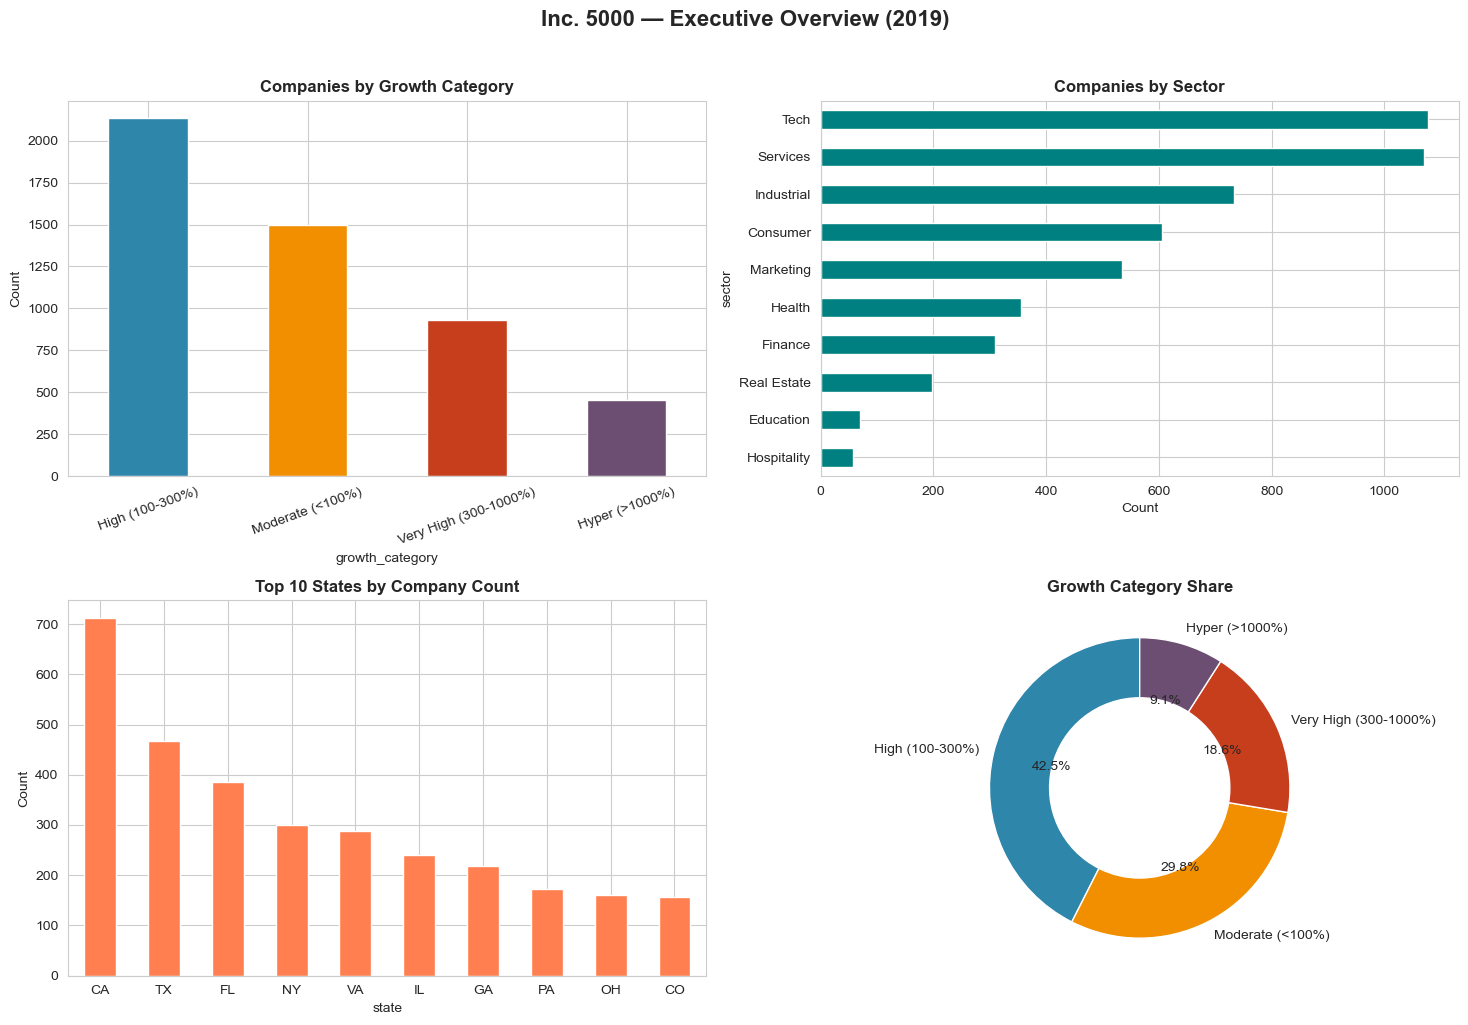

In [73]:
# ═══════════════════════════════════════════════════
# VIZ 1: Executive Overview — the "one-glance" panel
# ═══════════════════════════════════════════════════
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Top-left: Growth category distribution
df['growth_category'].value_counts().plot(
    kind='bar', ax=axes[0, 0], color=['#2E86AB', '#F18F01', '#C73E1D', '#6B4E71']
)
axes[0, 0].set_title('Companies by Growth Category', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Count')
axes[0, 0].tick_params(axis='x', rotation=20)

# Top-right: Sector distribution
df['sector'].value_counts().plot(
    kind='barh', ax=axes[0, 1], color='teal'
)
axes[0, 1].set_title('Companies by Sector', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Count')
axes[0, 1].invert_yaxis()

# Bottom-left: Top 10 states
df['state'].value_counts().head(10).plot(
    kind='bar', ax=axes[1, 0], color='coral'
)
axes[1, 0].set_title('Top 10 States by Company Count', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Count')
axes[1, 0].tick_params(axis='x', rotation=0)

# Bottom-right: Growth category donut
df['growth_category'].value_counts().plot(
    kind='pie', ax=axes[1, 1], autopct='%1.1f%%',
    colors=['#2E86AB', '#F18F01', '#C73E1D', '#6B4E71'],
    startangle=90, wedgeprops={'width': 0.4}
)
axes[1, 1].set_title('Growth Category Share', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('')

plt.suptitle('Inc. 5000 — Executive Overview (2019)',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

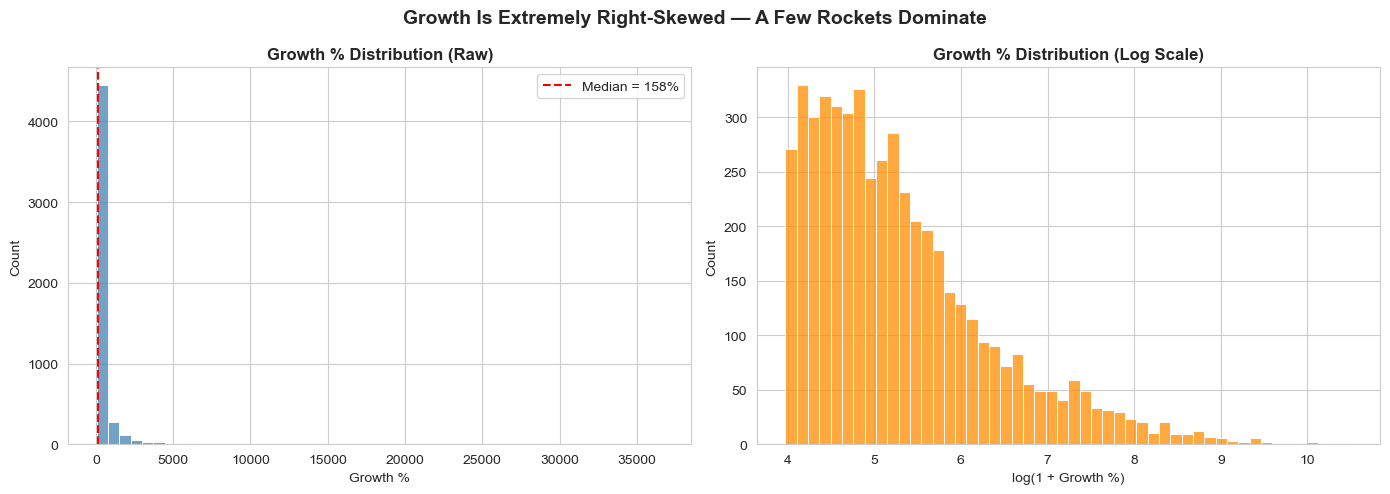

In [74]:
# ═══════════════════════════════════════════════════
# VIZ 2: Growth distribution — raw vs log scale
# ═══════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Raw — shows extreme right-skew (a few rockets)
sns.histplot(df['growth_%'], bins=50, ax=axes[0], color='steelblue')
axes[0].set_title('Growth % Distribution (Raw)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Growth %')
axes[0].axvline(df['growth_%'].median(), color='red', linestyle='--',
                label=f'Median = {df["growth_%"].median():.0f}%')
axes[0].legend()

# Right: Log scale — reveals the underlying shape
sns.histplot(np.log1p(df['growth_%']), bins=50, ax=axes[1], color='darkorange')
axes[1].set_title('Growth % Distribution (Log Scale)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('log(1 + Growth %)')

plt.suptitle('Growth Is Extremely Right-Skewed — A Few Rockets Dominate',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

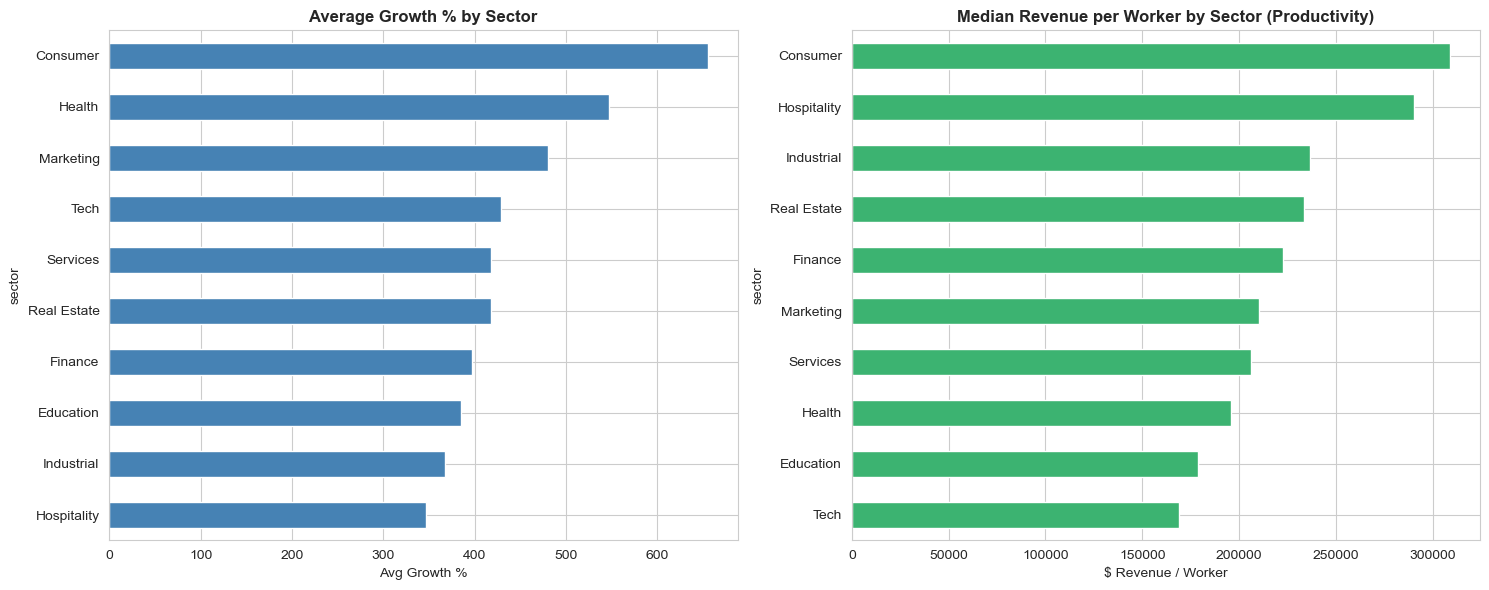

In [75]:
# ═══════════════════════════════════════════════════
# VIZ 3: Which sectors grow fastest & most efficiently?
# ═══════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left: Average growth by sector
sector_growth = (
    df.groupby('sector')['growth_%']
      .mean()
      .sort_values(ascending=True)
)
sector_growth.plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Average Growth % by Sector', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Avg Growth %')

# Right: Median revenue-per-worker by sector (productivity)
sector_rpw = (
    df.groupby('sector')['revenue_per_worker']
      .median()
      .sort_values(ascending=True)
)
sector_rpw.plot(kind='barh', ax=axes[1], color='mediumseagreen')
axes[1].set_title('Median Revenue per Worker by Sector (Productivity)',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('$ Revenue / Worker')

plt.tight_layout()
plt.show()

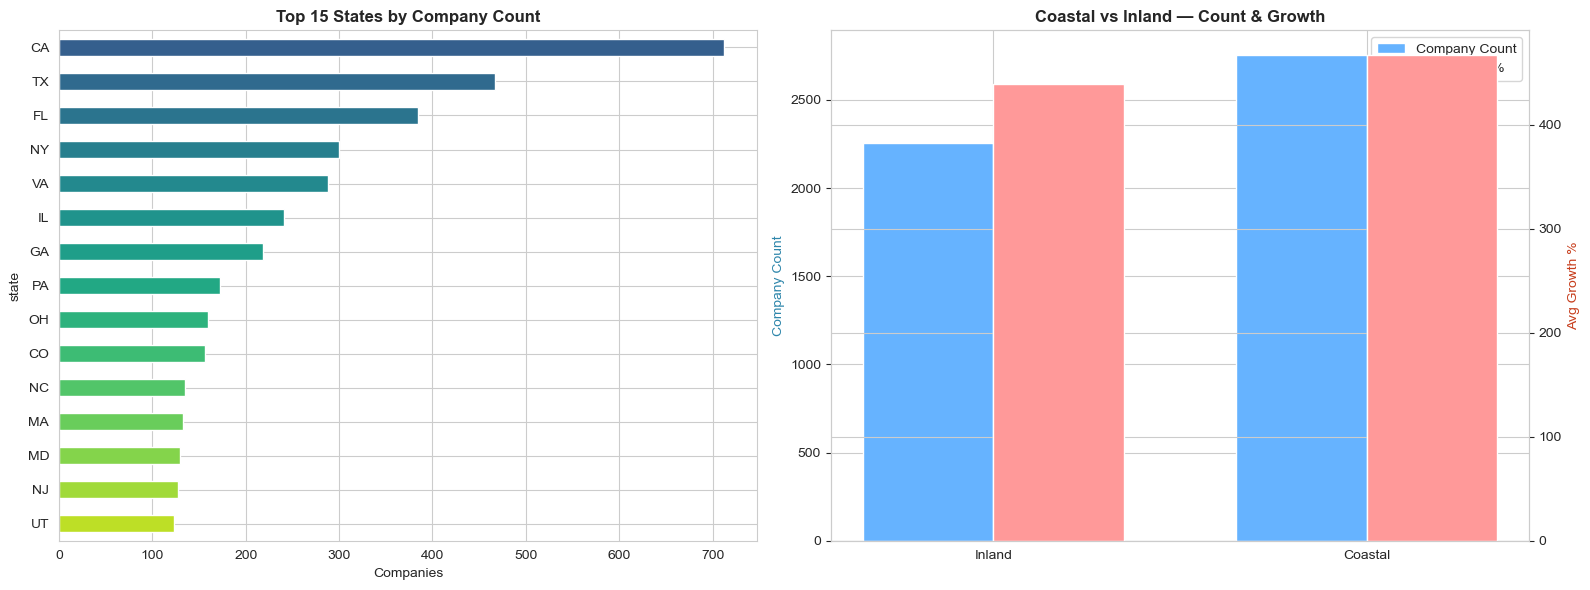

In [85]:
# ═══════════════════════════════════════════════════
# VIZ 4: Where are the high-growth companies?
# ═══════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: Top 15 states as horizontal bars
top_states = df['state'].value_counts().head(15)
top_states.plot(kind='barh', ax=axes[0],
                color=plt.cm.viridis(np.linspace(0.3, 0.9, 15)))
axes[0].invert_yaxis()
axes[0].set_title('Top 15 States by Company Count',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Companies')

# Right: Coastal vs Inland — count + avg growth
coastal_stats = df.groupby('is_coastal').agg(
    count=('name', 'count'),
    avg_growth=('growth_%', 'mean')
).reset_index()
coastal_stats['label'] = coastal_stats['is_coastal'].map(
    {True: 'Coastal', False: 'Inland'}
)

x = np.arange(len(coastal_stats))
width = 0.35
ax2 = axes[1]
b1 = ax2.bar(x - width/2, coastal_stats['count'], width,
             label='Company Count', color='#66b3ff')
ax2_twin = ax2.twinx()
b2 = ax2_twin.bar(x + width/2, coastal_stats['avg_growth'], width,
                  label='Avg Growth %', color='#ff9999')
ax2.set_xticks(x)
ax2.set_xticklabels(coastal_stats['label'])
ax2.set_ylabel('Company Count', color='#2E86AB')
ax2_twin.set_ylabel('Avg Growth %', color='#C73E1D')
ax2.set_title('Coastal vs Inland — Count & Growth',
              fontsize=12, fontweight='bold')
ax2.legend([b1, b2], ['Company Count', 'Avg Growth %'], loc='upper right')

plt.tight_layout()
plt.show()

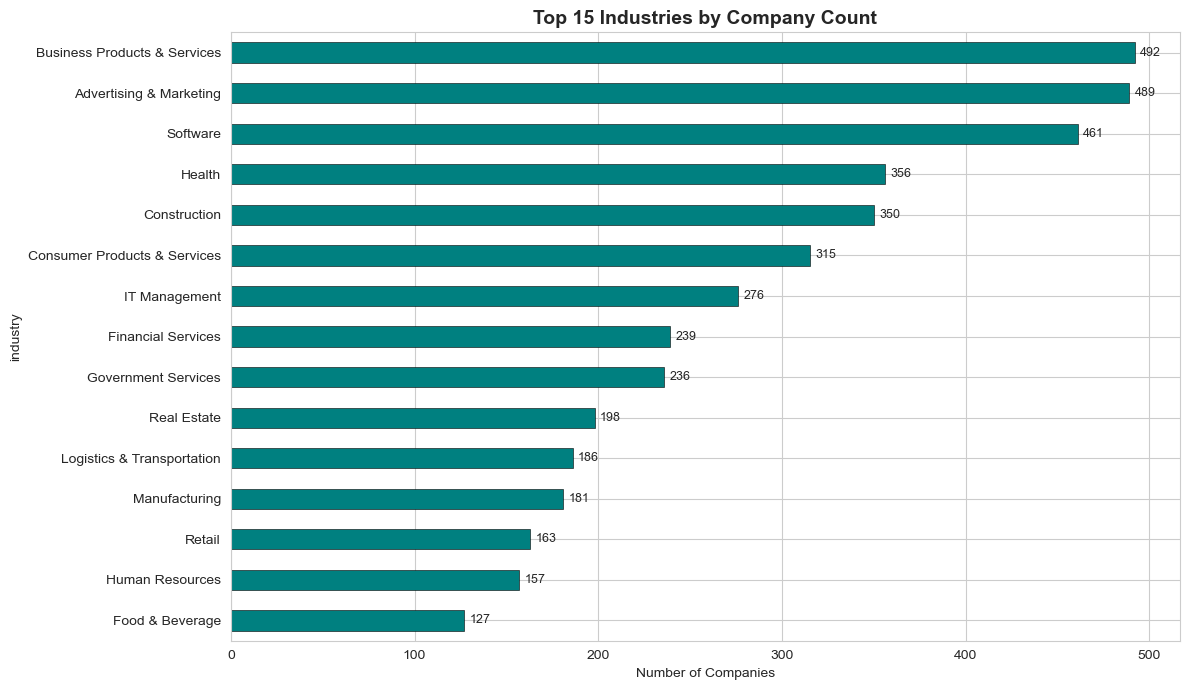

In [86]:
# ═══════════════════════════════════════════════════
# VIZ 5: Most common industries on the Inc. 5000
# ═══════════════════════════════════════════════════
plt.figure(figsize=(12, 7))
top_ind = df['industry'].value_counts().head(15)

top_ind.plot(kind='barh', color='teal', edgecolor='black', linewidth=0.4)
plt.gca().invert_yaxis()
plt.title('Top 15 Industries by Company Count', fontsize=14, fontweight='bold')
plt.xlabel('Number of Companies')

# Add value labels on each bar
for i, v in enumerate(top_ind.values):
    plt.text(v + 3, i, str(v), va='center', fontsize=9)

plt.tight_layout()
plt.show()

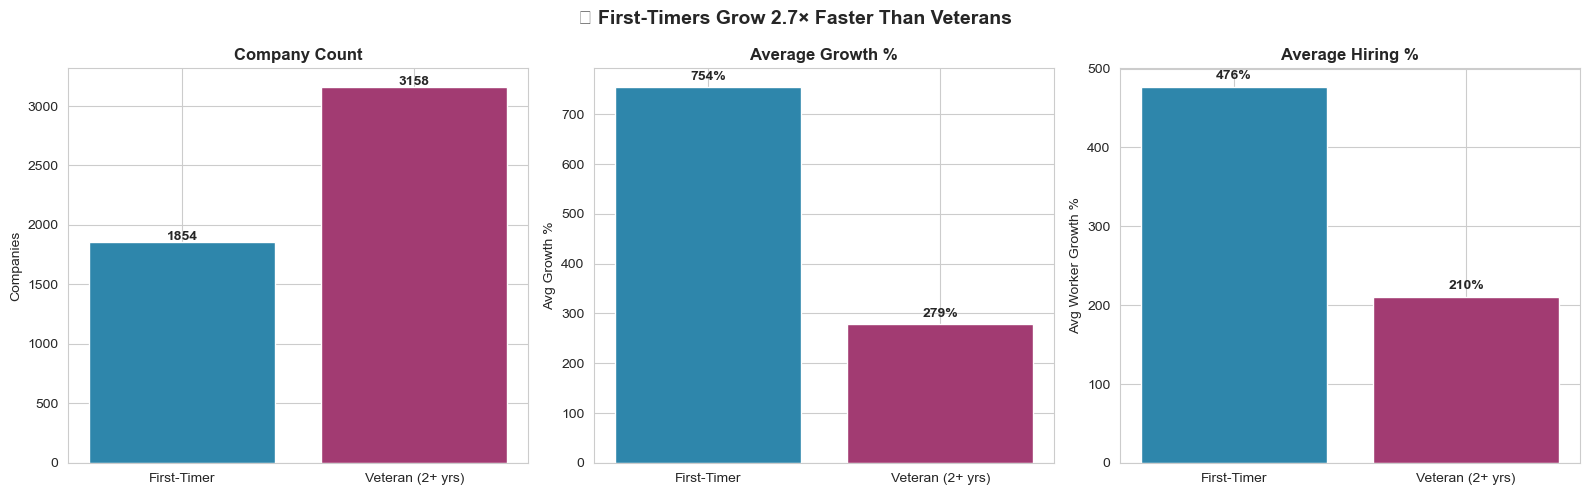

In [87]:
# ═══════════════════════════════════════════════════
# VIZ 6: Do repeat-list companies grow faster?
# (SPOILER: NO — first-timers do, by 2.7×)
# ═══════════════════════════════════════════════════
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

labels = ['First-Timer', 'Veteran (2+ yrs)']

# Left: Company count
counts = df.groupby('is_veteran').size().values
axes[0].bar(labels, counts, color=['#2E86AB', '#A23B72'])
axes[0].set_title('Company Count', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Companies')
for i, v in enumerate(counts):
    axes[0].text(i, v + 20, str(v), ha='center', fontweight='bold')

# Middle: Average growth %
growth = df.groupby('is_veteran')['growth_%'].mean().values
axes[1].bar(labels, growth, color=['#2E86AB', '#A23B72'])
axes[1].set_title('Average Growth %', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Avg Growth %')
for i, v in enumerate(growth):
    axes[1].text(i, v + 15, f'{v:.0f}%', ha='center', fontweight='bold')

# Right: Average hiring %
hiring = df.groupby('is_veteran')['worker_growth_pct'].mean().values
axes[2].bar(labels, hiring, color=['#2E86AB', '#A23B72'])
axes[2].set_title('Average Hiring %', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Avg Worker Growth %')
for i, v in enumerate(hiring):
    axes[2].text(i, v + 10, f'{v:.0f}%', ha='center', fontweight='bold')

plt.suptitle('🚀 First-Timers Grow 2.7× Faster Than Veterans',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

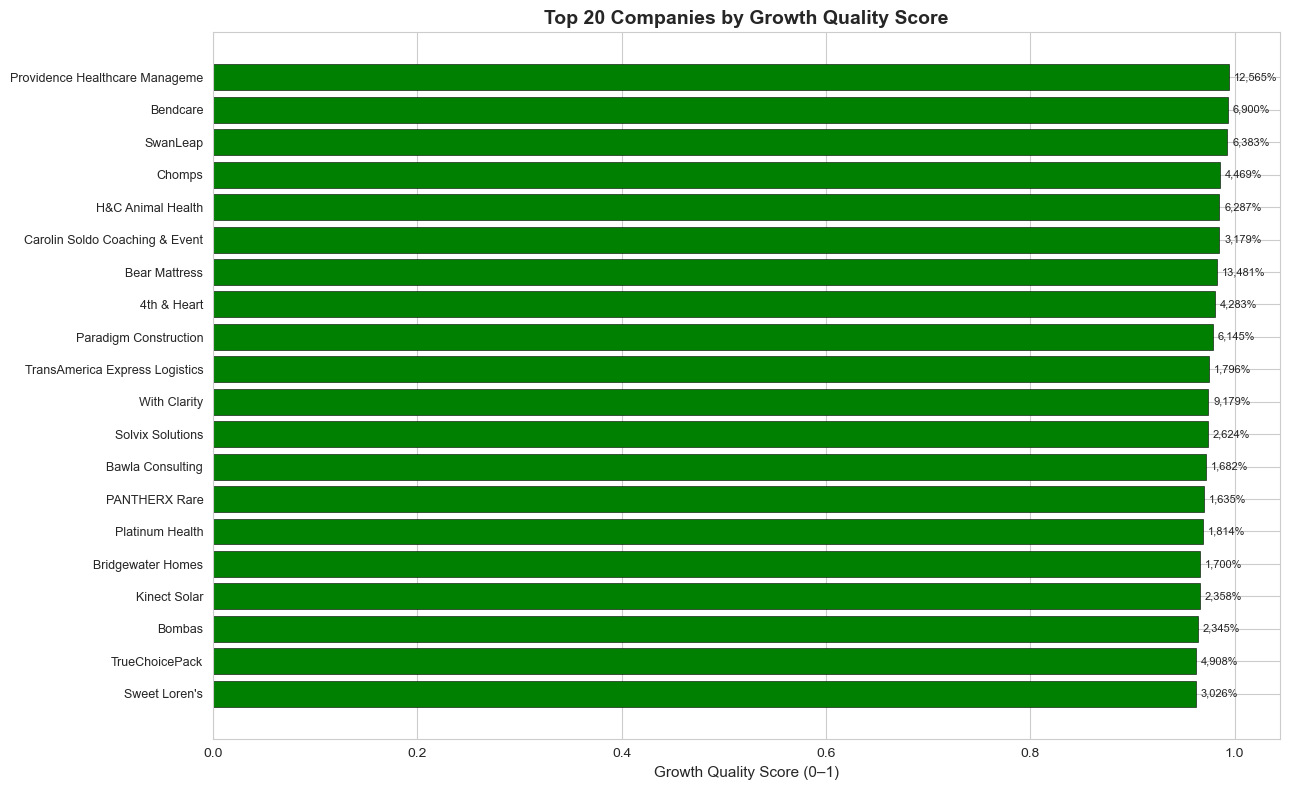

In [88]:
# ═══════════════════════════════════════════════════
# VIZ 7: Our composite "best companies" — top 20
# ═══════════════════════════════════════════════════
top20 = df.nlargest(20, 'growth_quality_score')[
    ['name', 'sector', 'growth_%', 'revenue_per_worker',
     'growth_quality_score', 'scaling_type']
].copy()

fig, ax = plt.subplots(figsize=(13, 8))
colors_bar = top20['scaling_type'].map({
    'Efficient Scaler': 'green',
    'Brute Scaler': 'orange',
    'Efficient but Slow': 'royalblue',
    'Lagging': 'red',
})

bars = ax.barh(range(len(top20)), top20['growth_quality_score'],
               color=colors_bar, edgecolor='black', linewidth=0.4)
ax.set_yticks(range(len(top20)))
ax.set_yticklabels([f"{n[:30]}" for n in top20['name']], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Growth Quality Score (0–1)', fontsize=11)
ax.set_title('Top 20 Companies by Growth Quality Score',
             fontsize=14, fontweight='bold')

# Add growth % label on each bar
for i, (score, gr) in enumerate(zip(top20['growth_quality_score'],
                                     top20['growth_%'])):
    ax.text(score + 0.005, i, f'{gr:,.0f}%', va='center', fontsize=8)

plt.tight_layout()
plt.show()

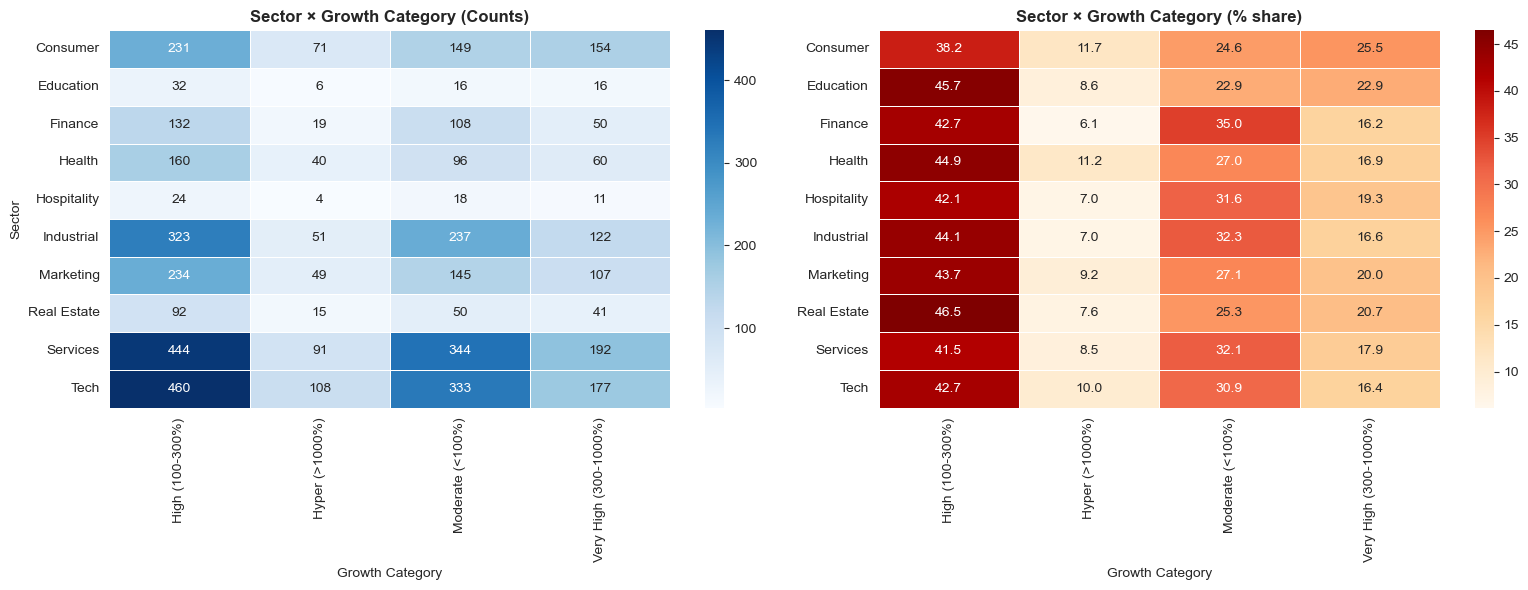

In [89]:
# ═══════════════════════════════════════════════════
# VIZ 8: Which sector has the most hyper-growers?
# ═══════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: Absolute counts
cross = pd.crosstab(df['sector'], df['growth_category'])
sns.heatmap(cross, annot=True, fmt='d', cmap='Blues',
            ax=axes[0], linewidths=0.5)
axes[0].set_title('Sector × Growth Category (Counts)',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Growth Category')
axes[0].set_ylabel('Sector')

# Right: Row-normalized (share of each sector in each growth band)
cross_pct = cross.div(cross.sum(axis=1), axis=0) * 100
sns.heatmap(cross_pct, annot=True, fmt='.1f', cmap='OrRd',
            ax=axes[1], linewidths=0.5)
axes[1].set_title('Sector × Growth Category (% share)',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('Growth Category')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

In [90]:
# Export to CSV
output_file = 'INC_5000_Companies_clean.csv'
df.to_csv(output_file, index=False)

# Inc. 5000 Companies 2019 — Data Cleaning & Feature Engineering

**Notebook:** `INC_5000_Companies_code.ipynb`
**Input:** `INC 5000 Companies 2019.csv` (5,012 rows × 14 cols)
**Output:** `INC_5000_Companies_clean.csv` (5,012 rows × 44 cols)

This notebook cleans the raw Inc. 5000 dataset and engineers 30 new analytical features for SQL and Power BI analysis.

---

## Workflow

### 1. Load & Audit
- Load raw CSV with pandas
- Check dtypes, missing values, duplicate ranks, numeric ranges

### 2. Data Cleaning
- **`revenue`** → parsed "36.9 Million" / "1.2 Billion" text to numeric `revenue_usd`
- **`url`** → added `http://` where missing
- **Numeric cols** → forced types with `pd.to_numeric(errors='coerce')`
- **`metro`** → stripped state suffix → `metro_clean`; blanks → `'Unknown'`
- **Text cols** → stripped whitespace

### 3. Data Quality Fixes
- `founded = 0` → `NaN` (1 row — impossible year)
- `workers = 0` → `NaN` (1 row — prevents divide-by-zero)
- Flagged 12 tie-rank rows → `is_tie_rank`

### 4. Feature Engineering (30 new columns)

**Financial:** `revenue_usd`, `revenue_category`, `is_billion_club`, `revenue_per_worker`, `revenue_per_year_of_existence`

**Growth:** `growth_category`, `growth_percentile`, `industry_avg_growth`, `growth_vs_industry_avg`, `growth_vs_state_avg`, `growth_per_worker`

**Workforce:** `worker_growth_abs`, `worker_growth_pct`, `is_lean_team`, `worker_bucket`

**Time:** `company_age`, `age_bucket`, `is_veteran`, `founded_decade`

**Geography:** `region`, `is_coastal`, `has_metro_data`, `metro_clean`

**Sector:** `sector` (maps 20+ industries → 10 sectors)

**Composite ⭐:** `rpw_percentile`, `growth_quality_score`, `scaling_type` (Efficient/Brute/Efficient-Slow/Lagging), `rank_percentile`

### 5. Visualizations (8 charts)
1. Executive overview (4-panel)
2. Growth distribution (raw + log)
3. Sector performance (growth + productivity)
4. **Scaling quadrant** (BCG-style matrix)
5. Top 15 states
6. Top 15 industries
7. **Veteran vs first-timer** comparison
8. Top 20 companies by quality score

### 6. Export
- Validated 18 critical columns present
- Exported to `INC_5000_Companies_clean.csv` → ready for SQLite + Power BI

---

## Key Outputs

| Metric | Value |
|---|---|
| Total Revenue | $237.92 Billion |
| Total Workers | 1.2 Million |
| Avg Growth | 454.7% |
| Median Growth | 157.5% |
| First-timers avg growth | 754% (2.7× veterans) |
| Efficient Scalers | ~26% of list |

---


In [91]:
pip install pymysql sqlalchemy

Note: you may need to restart the kernel to use updated packages.


In [92]:
# ═══════════════════════════════════════════════════════════════
# STEP A: Connect to MySQL
# ═══════════════════════════════════════════════════════════════

from sqlalchemy import create_engine
from urllib.parse import quote_plus   # safe for passwords with special chars
import pandas as pd

# ── Connection ──
USER     = 'root'
PASSWORD = quote_plus('1234')         # encoded — safe even if password changes
HOST     = 'localhost'
PORT     = 3306                        # MySQL default
DATABASE = 'inc5000_analytics'

engine = create_engine(
    f"mysql+pymysql://{USER}:{PASSWORD}@{HOST}:{PORT}/{DATABASE}"
)

# ── Test connection before loading (fails fast if credentials are wrong) ──
with engine.connect() as conn:
    from sqlalchemy import text
    version = conn.execute(text("SELECT VERSION();")).scalar()
    print(f"✓ Connected to MySQL {version}")

# ── Load DataFrame into `customer` table ──
df.to_sql(
    name='companies',
    con=engine,
    if_exists='replace',    # drop & recreate on every run — safe while iterating
    index=False,
    chunksize=1000,
)

print(f"✓ Loaded {len(df):,} rows × {df.shape[1]} columns → {DATABASE}.customer")

✓ Connected to MySQL 8.0.44
✓ Loaded 5,012 rows × 44 columns → inc5000_analytics.customer


In [93]:
df.shape

(5012, 44)

In [96]:
## Verify it actually loaded (separate cell)

# Row count sanity check — must equal 3900
row_count = pd.read_sql("SELECT COUNT(*) AS n FROM companies;", engine)
print(row_count)

# Spot-check: first 5 rows
pd.read_sql("SELECT * FROM companies LIMIT 5;", engine)

      n
0  5012


,rank,profile,name,url,state,revenue,growth_%,industry,workers,previous_workers,founded,yrs_on_list,metro,city,revenue_usd,metro_clean,is_tie_rank,revenue_category,is_billion_club,revenue_per_worker,growth_category,growth_percentile,industry_avg_growth,growth_vs_industry_avg,state_avg_growth,growth_vs_state_avg,growth_per_worker,worker_growth_abs,worker_growth_pct,is_lean_team,worker_bucket,company_age,revenue_per_year_of_existence,age_bucket,is_veteran,founded_decade,region,is_coastal,has_metro_data,sector,rpw_percentile,growth_quality_score,scaling_type,rank_percentile
0,1,https://www.inc.com/profile/freestar,Freestar,http://freestar.com,AZ,36.9 Million,36680.3882,Advertising & Marketing,40.0,5,2015.0,1,Phoenix,Phoenix,36900000.0,Phoenix,0,10-50M,0,922500.000000,Hyper (>1000%),1.000000,486.685136,36193.703064,702.485563,35977.902638,917.009705,35.0,700.000000,0,20-99,4.0,9225000.0,0-5 yrs,0,2010,West,0,1,Marketing,0.913521,0.956761,Efficient Scaler,0.9998
1,2,https://www.inc.com/profile/freightwise,FreightWise,http://freightwisellc.com,TN,33.6 Million,30547.9317,Logistics & Transportation,39.0,8,2015.0,1,Nashville,Brentwood,33600000.0,Nashville,0,10-50M,0,861538.461538,Hyper (>1000%),0.999800,717.563346,29830.368354,734.200479,29813.731221,783.280300,31.0,387.500000,0,20-99,4.0,8400000.0,0-5 yrs,0,2010,South,0,1,Services,0.902736,0.951268,Efficient Scaler,0.9996
2,3,https://www.inc.com/profile/ceces-veggie,Cece's Veggie Co.,http://cecesveggieco.com,TX,24.9 Million,23880.4852,Food & Beverage,190.0,10,2015.0,1,Austin,Austin,24900000.0,Austin,0,10-50M,0,131052.631579,Hyper (>1000%),0.999601,668.225534,23212.259666,433.899806,23446.585394,125.686764,180.0,1800.000000,0,100-499,4.0,6225000.0,0-5 yrs,0,2010,South,0,1,Consumer,0.263631,0.631616,Brute Scaler,0.9994
3,4,https://www.inc.com/profile/ladyboss,LadyBoss,http://ladyboss.com,NM,32.4 Million,21849.8925,Consumer Products & Services,57.0,2,2014.0,1,None,Albuquerque,32400000.0,Unknown,0,10-50M,0,568421.052632,Hyper (>1000%),0.999401,685.640300,21164.252200,3259.421014,18590.471486,383.331447,55.0,2750.000000,0,20-99,5.0,6480000.0,0-5 yrs,0,2010,West,0,0,Consumer,0.832435,0.915918,Efficient Scaler,0.9992
4,5,https://www.inc.com/profile/perpay,Perpay,http://perpay.com,PA,22.5 Million,18166.4070,Retail,25.0,6,2014.0,1,Philadelphia,Philadelphia,22500000.0,Philadelphia,0,10-50M,0,900000.000000,Hyper (>1000%),0.999202,584.823802,17581.583198,401.730816,17764.676184,726.656280,19.0,316.666667,0,20-99,5.0,4500000.0,0-5 yrs,0,2010,Northeast,0,1,Consumer,0.910126,0.954664,Efficient Scaler,0.9990


In [97]:
# See ALL column names currently in the MySQL table
pd.read_sql("SHOW COLUMNS FROM companies;", engine)

,Field,Type,Null,Key,Default,Extra
0,rank,bigint,YES,,None,
1,profile,text,YES,,None,
2,name,text,YES,,None,
3,url,text,YES,,None,
4,state,text,YES,,None,
5,revenue,text,YES,,None,
6,growth_%,double,YES,,None,
7,industry,text,YES,,None,
8,workers,double,YES,,None,
9,previous_workers,bigint,YES,,None,


In [98]:
# ═══════════════════════════════════════════════════════════════
# Rename 3 problem columns directly in MySQL (no reload needed)
# ═══════════════════════════════════════════════════════════════
from sqlalchemy import text

with engine.connect() as conn:
    # 1. rank → company_rank (RANK is a reserved keyword)
    conn.execute(text("ALTER TABLE companies CHANGE `rank` company_rank BIGINT;"))
    
    # 2. growth_% → growth_pct (% breaks SQL parsing)
    conn.execute(text("ALTER TABLE companies CHANGE `growth_%` growth_pct DOUBLE;"))
    
    # 3. Long name → short name
    conn.execute(text("ALTER TABLE companies CHANGE growth_vs_industry_avg growth_vs_ind_avg DOUBLE;"))
    
    conn.commit()
    print("✓ All 3 columns renamed successfully")

# Verify the fix
cols = pd.read_sql("SHOW COLUMNS FROM companies;", engine)
print("\n✓ Confirmed columns:")
print(cols[cols['Field'].isin(['company_rank', 'growth_pct', 'growth_vs_ind_avg'])][['Field', 'Type']])

✓ All 3 columns renamed successfully

✓ Confirmed columns:
                Field    Type
0        company_rank  bigint
6          growth_pct  double
23  growth_vs_ind_avg  double


In [99]:
# This should work immediately after the fix
pd.read_sql("""
    SELECT COUNT(*)                          AS total_companies,
           ROUND(SUM(revenue_usd) / 1e9, 2)  AS total_revenue_billions,
           SUM(workers)                      AS total_workers,
           ROUND(AVG(growth_pct), 1)         AS avg_growth_pct,
           MIN(founded)                      AS oldest_company_founded,
           MAX(founded)                      AS newest_company_founded
    FROM companies;
""", engine)

,total_companies,total_revenue_billions,total_workers,avg_growth_pct,oldest_company_founded,newest_company_founded
0,5012,237.92,1216586.0,454.7,1869.0,2016.0
